In [5]:
image_path = "/home/kree/Pictures/blueblack.jpg"

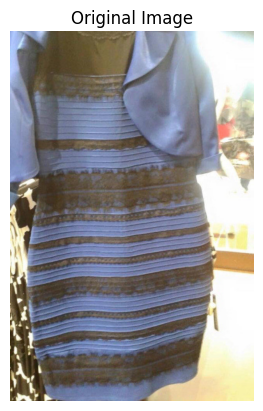

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_image(image, title="Image"):
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

# Load the image
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not found. Please check the path.") 

# rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
show_image(image, "Original Image") 

In [10]:
np_image = np.array(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
print("Image shape:", np_image.shape)
print("Image dtype:", np_image.dtype)

Image shape: (750, 495, 3)
Image dtype: uint8


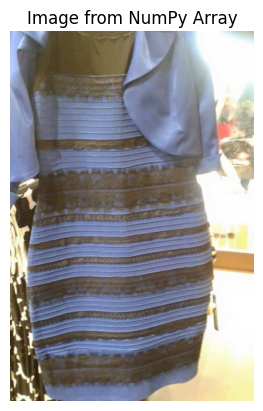

In [11]:
plt.imshow(np_image)
plt.title("Image from NumPy Array")
plt.axis('off')
plt.show()

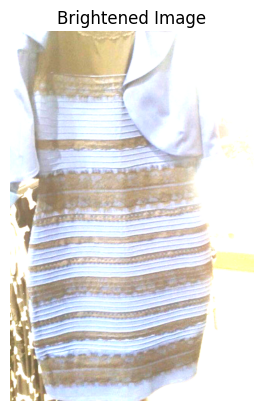

In [12]:
bright_img = cv2.convertScaleAbs(image, alpha=1.5, beta=50)
show_image(bright_img, "Brightened Image")

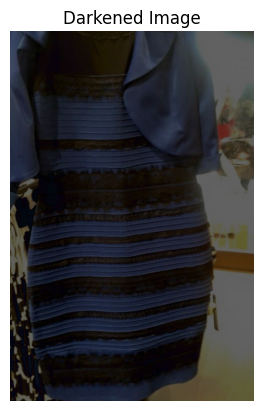

In [21]:
# reduce brightness
dark_img = cv2.convertScaleAbs(image, alpha=0.5, beta=-30)
show_image(dark_img, "Darkened Image")

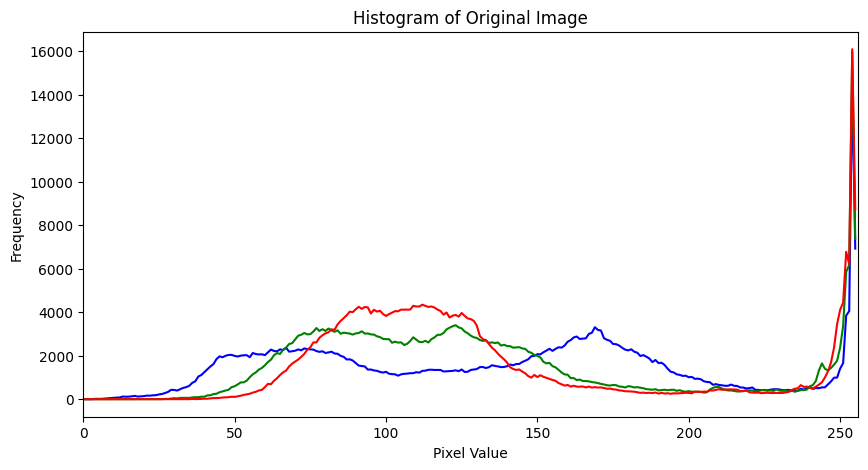

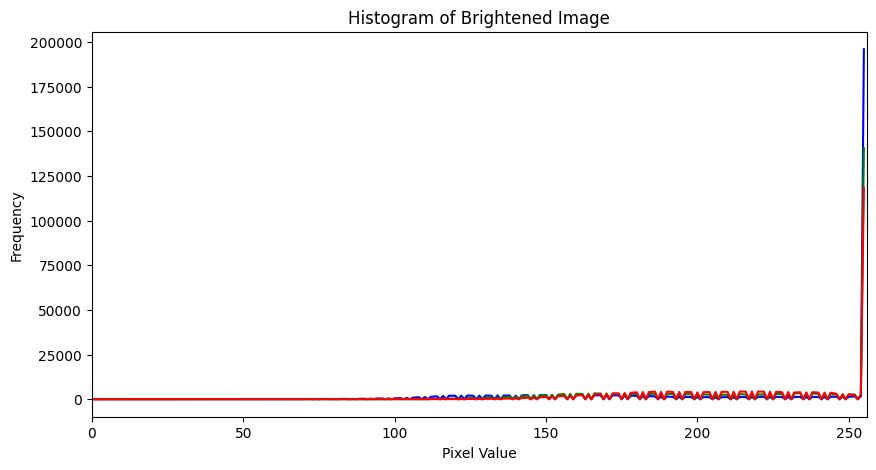

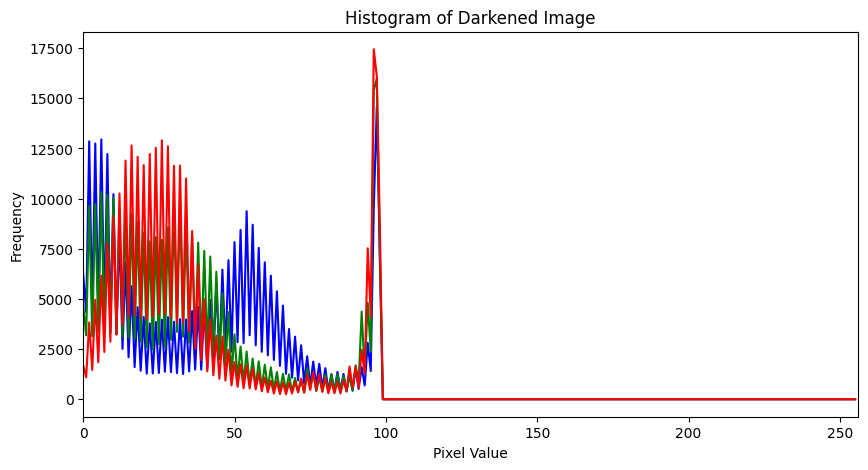

In [23]:
# histogram plot
def plot_histogram(image, title="Histogram"):
    color = ('b', 'g', 'r')
    plt.figure(figsize=(10, 5))
    for i, col in enumerate(color):
        hist = cv2.calcHist([image], [i], None, [256], [0, 256])
        plt.plot(hist, color=col)
        plt.xlim([0, 256])
    plt.title(title)
    plt.xlabel('Pixel Value')
    plt.ylabel('Frequency')
    plt.show()

plot_histogram(image, "Histogram of Original Image")
plot_histogram(bright_img, "Histogram of Brightened Image")
plot_histogram(dark_img, "Histogram of Darkened Image")


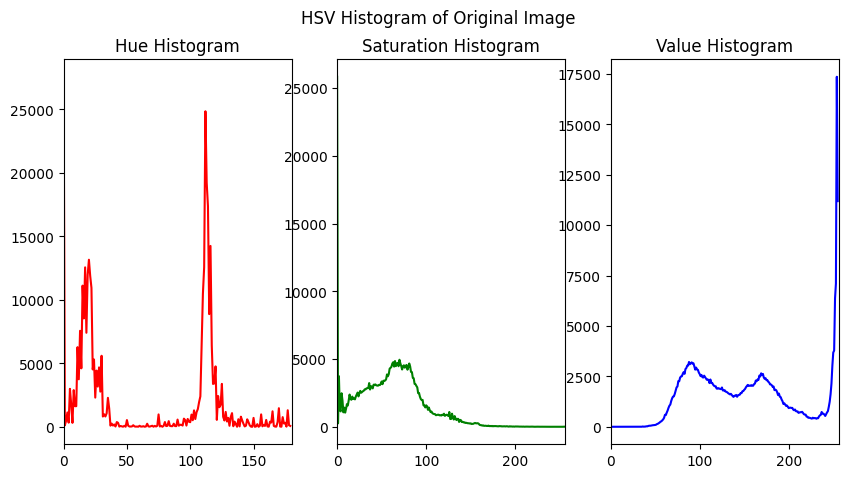

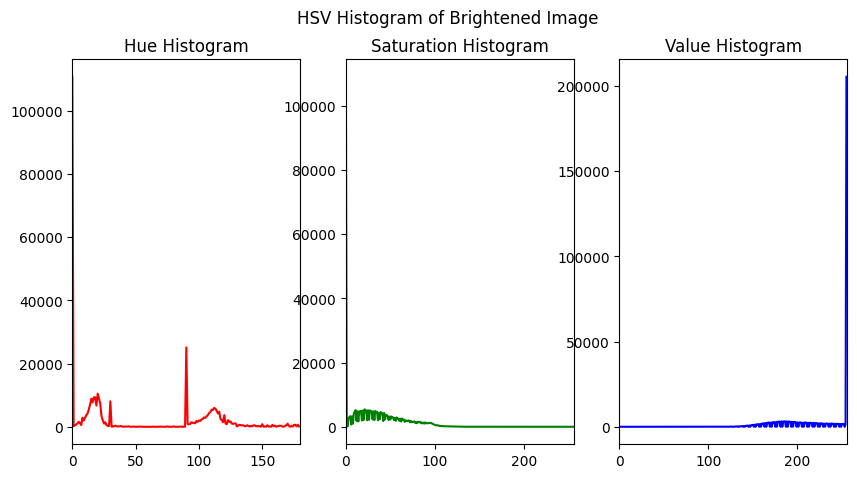

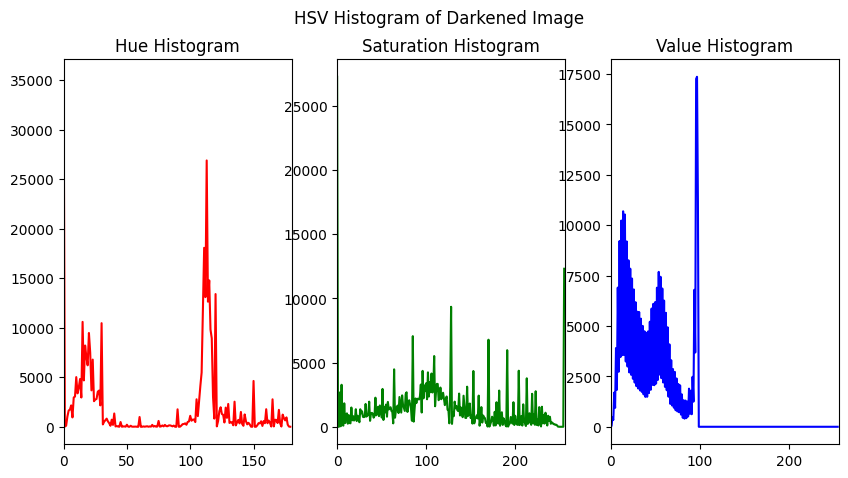

In [24]:
# HSV space plot
def plot_hsv_histogram(image, title="HSV Histogram"):
    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h_hist = cv2.calcHist([hsv_image], [0], None, [180], [0, 180])
    s_hist = cv2.calcHist([hsv_image], [1], None, [256], [0, 256])
    v_hist = cv2.calcHist([hsv_image], [2], None, [256], [0, 256])

    plt.figure(figsize=(10, 5))
    plt.subplot(131)
    plt.plot(h_hist, color='r')
    plt.title('Hue Histogram')
    plt.xlim([0, 180])

    plt.subplot(132)
    plt.plot(s_hist, color='g')
    plt.title('Saturation Histogram')
    plt.xlim([0, 256])

    plt.subplot(133)
    plt.plot(v_hist, color='b')
    plt.title('Value Histogram')
    plt.xlim([0, 256])

    plt.suptitle(title)
    plt.show()
plot_hsv_histogram(image, "HSV Histogram of Original Image")
plot_hsv_histogram(bright_img, "HSV Histogram of Brightened Image")
plot_hsv_histogram(dark_img, "HSV Histogram of Darkened Image")